# Examen de Big Data – Spark ML
## Parte 2 · Clasificación multiclase de deserción estudiantil

**Estudiante:** Miguel Ángel Solano Díaz  **ID:** U00177983
**Universidad Autónoma de Bucaramanga (UNAB) – Ingeniería de Sistemas**

**Objetivo.** Construir con Spark ML un modelo que clasifique a cada estudiante en una de tres clases para detectar a tiempo a quienes están en riesgo:

| Clase | Significado |
|---|---|
| **Dropout** | El estudiante abandonó la carrera |
| **Enrolled** | Sigue matriculado, pero no se graduó en el tiempo normal |
| **Graduate** | Se graduó en el tiempo normal |

**Dataset.** *Predict Students' Dropout and Academic Success* (Kaggle / UCI): 4.424 estudiantes, 34 variables demográficas, socioeconómicas, macroeconómicas y de rendimiento académico, más la variable objetivo `Target` (versión `dataset.csv`, separada por comas).

**Organización del notebook**
- **Sección A.** Carga, limpieza, ingeniería de características y partición (tareas 1 a 3)
- **Sección B.** Pipelines, hiperparametrización y validación cruzada (tareas 4 y 5)
- **Sección C.** Evaluación, selección y guardado del mejor modelo (tarea 6)

> Todas las celdas de código van precedidas de una celda de texto que explica **qué hace y por qué**.

### 0.1 Preparación del entorno (PySpark y Java)

**Qué hace:** verifica la versión de PySpark y de Java del entorno; si no coinciden con lo requerido, instala **PySpark 4.0.5** y **OpenJDK 17**.

**Por qué:**
- La aplicación de Streamlit cargará el modelo con `PipelineModel.load`. Para que el modelo guardado aquí cargue sin errores allá, **ambos lados deben usar exactamente la misma versión de PySpark** (la misma que irá en `requirements.txt`).
- Spark 4 necesita Java 17 o superior. Streamlit Community Cloud instala Java 17/21 con `default-jre`, así que entrenar aquí con Java 17 deja todo compatible.
- Se usa `importlib.metadata` para consultar la versión **sin importar** PySpark todavía; así, si hay que reinstalarlo, el kernel no queda con la versión vieja cargada en memoria.

In [1]:
import os, re, sys, subprocess, importlib.metadata

PYSPARK_VERSION = "4.0.5"
EN_COLAB = "google.colab" in sys.modules

# 1) PySpark: instalar la versión fijada si no es la que está en el entorno
try:
    version_actual = importlib.metadata.version("pyspark")
except importlib.metadata.PackageNotFoundError:
    version_actual = None

if version_actual != PYSPARK_VERSION:
    print(f"PySpark actual: {version_actual} -> instalando pyspark=={PYSPARK_VERSION} ...")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", f"pyspark=={PYSPARK_VERSION}"], check=True)
else:
    print(f"PySpark {PYSPARK_VERSION} ya está instalado.")

# 2) Java: Spark 4 requiere Java 17+
def version_java():
    try:
        salida = subprocess.run(["java", "-version"], capture_output=True, text=True).stderr
        m = re.search(r'version "(\d+)', salida)
        return int(m.group(1)) if m else None
    except FileNotFoundError:
        return None

if (version_java() or 0) < 17:
    print("Instalando OpenJDK 17 (tarda ~1 minuto) ...")
    subprocess.run("apt-get update -qq && apt-get install -y -qq openjdk-17-jdk-headless > /dev/null",
                   shell=True, check=True)
    os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"
    os.environ["PATH"] = os.environ["JAVA_HOME"] + "/bin:" + os.environ["PATH"]

print("Java:", version_java(), "| Python:", sys.version.split()[0], "| Colab:", EN_COLAB)

PySpark 4.0.5 ya está instalado.
Java: 21 | Python: 3.13.18 | Colab: True


### 0.2 Importación de librerías

**Qué hace:** importa los módulos de Spark SQL, Spark ML y las librerías de apoyo (pandas y matplotlib solo para mostrar tablas y gráficos de resultados pequeños).

**Por qué:** todo el procesamiento de datos y el entrenamiento se hacen con Spark; pandas/matplotlib se usan únicamente para visualizar resúmenes ya agregados.

In [2]:
import json, time, shutil, warnings
warnings.filterwarnings("ignore")

import pandas as pd
import matplotlib.pyplot as plt

import pyspark
from pyspark.sql import SparkSession, functions as F
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler
from pyspark.ml.classification import (LogisticRegression, RandomForestClassifier,
                                       DecisionTreeClassifier)
from pyspark.ml.evaluation import MulticlassClassificationEvaluator
from pyspark.ml.tuning import ParamGridBuilder, CrossValidator

pd.set_option("display.max_rows", 100)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
print("PySpark", pyspark.__version__)

PySpark 4.0.5


---
# Sección A · Carga, limpieza, ingeniería de características y partición
## Tarea 1 · Carga y exploración

### 1.1 Creación de la SparkSession

**Qué hace:** crea la sesión de Spark con `SparkSession.builder`.

**Por qué cada configuración:**
| Configuración | Motivo |
|---|---|
| `spark.driver.memory = 4g` | En Colab la memoria del driver por defecto es limitada (nota del enunciado). |
| `spark.sql.constraintPropagation.enabled = false` | Evita la "explosión" del optimizador con planes que tienen muchas columnas derivadas (nota del enunciado). |
| `spark.sql.shuffle.partitions = 4` | El dataset es pequeño (~4.400 filas). Con el valor por defecto (200), cada *shuffle* crearía 200 tareas casi vacías y la validación cruzada sería muy lenta. El enunciado pide **máximo 4 particiones**. |
| `spark.default.parallelism = 4` | Mismo criterio para operaciones sobre RDD. |

In [3]:
spark = (SparkSession.builder
         .appName("dropout_sparkml")
         .config("spark.driver.memory", "4g")
         .config("spark.sql.constraintPropagation.enabled", "false")  # evita la explosión del optimizador
         .config("spark.sql.shuffle.partitions", "4")                  # dataset pequeño: máximo 4 particiones
         .config("spark.default.parallelism", "4")
         .config("spark.ui.showConsoleProgress", "false")              # sin barras de progreso en las salidas
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")

print("Spark versión :", spark.version)
print("Shuffle partitions:", spark.conf.get("spark.sql.shuffle.partitions"))

Spark versión : 4.0.5
Shuffle partitions: 4


### 1.2 Ubicación del archivo y detección del separador

**Qué hace:** busca `data.csv` en la carpeta de trabajo (si no existe y estamos en Colab, abre el diálogo para subirlo) y **detecta el separador** leyendo solo la primera línea.

**Por qué:** el enunciado indica que el archivo usa punto y coma (`;`), pero el ejemplo de lectura usa coma (`,`) y hay dos versiones del dataset en Kaggle (la original usa `;` y la de *thedevastator* usa `,`). En lugar de suponer, se cuenta cuál carácter aparece más en el encabezado. Así el notebook funciona con cualquiera de las dos versiones y queda la evidencia del separador correcto.

In [4]:
RUTA_CSV = "data.csv"

if not os.path.exists(RUTA_CSV) and EN_COLAB:
    from google.colab import files
    print("No se encontró data.csv. Selecciona el archivo CSV del dataset:")
    subidos = files.upload()
    RUTA_CSV = next(iter(subidos))

with open(RUTA_CSV, encoding="utf-8-sig") as f:
    encabezado = f.readline()

SEP = ";" if encabezado.count(";") > encabezado.count(",") else ","
print(f"Archivo: {RUTA_CSV}")
print(f"Separador detectado: '{SEP}'  ->  ';' aparece {encabezado.count(';')} veces, "
      f"',' aparece {encabezado.count(',')} veces en el encabezado")

No se encontró data.csv. Selecciona el archivo CSV del dataset:


Saving dataset.csv to dataset (1).csv
Archivo: dataset (1).csv
Separador detectado: ','  ->  ';' aparece 0 veces, ',' aparece 34 veces en el encabezado


### 1.3 Lectura del CSV con Spark

**Qué hace:** lee el CSV con `spark.read.csv` indicando `header=True` (la primera fila son los nombres de columna), `inferSchema=True` (Spark deduce si cada columna es entera, decimal o texto) y el separador detectado. Luego reparte los datos en **4 particiones** y los deja en caché.

**Por qué:** sin `inferSchema` todas las columnas quedarían como texto; sin el separador correcto Spark leería una sola columna gigante. `repartition(4)` cumple el límite de particiones y `cache()` evita releer el archivo en cada acción (conteos, validación cruzada, etc.).

In [5]:
df_raw = spark.read.csv(RUTA_CSV, header=True, inferSchema=True, sep=SEP)
df_raw = df_raw.repartition(4).cache()

print("Particiones:", df_raw.rdd.getNumPartitions())
df_raw.printSchema()

Particiones: 4
root
 |-- Marital status: integer (nullable = true)
 |-- Application mode: integer (nullable = true)
 |-- Application order: integer (nullable = true)
 |-- Course: integer (nullable = true)
 |-- Daytime/evening attendance: integer (nullable = true)
 |-- Previous qualification: integer (nullable = true)
 |-- Nacionality: integer (nullable = true)
 |-- Mother's qualification: integer (nullable = true)
 |-- Father's qualification: integer (nullable = true)
 |-- Mother's occupation: integer (nullable = true)
 |-- Father's occupation: integer (nullable = true)
 |-- Displaced: integer (nullable = true)
 |-- Educational special needs: integer (nullable = true)
 |-- Debtor: integer (nullable = true)
 |-- Tuition fees up to date: integer (nullable = true)
 |-- Gender: integer (nullable = true)
 |-- Scholarship holder: integer (nullable = true)
 |-- Age at enrollment: integer (nullable = true)
 |-- International: integer (nullable = true)
 |-- Curricular units 1st sem (credited): 

### 1.4 Dimensiones y primeras filas

**Qué hace:** cuenta filas y columnas y muestra las primeras 5 filas.

**Por qué:** confirma que se cargaron los ~4.400 estudiantes y las 35 columnas de esta versión del archivo (34 variables + `Target`) y permite ver de un vistazo que las variables categóricas vienen **codificadas como números** (por ejemplo, `Course` = 11), un detalle clave para la ingeniería de características.

In [6]:
n_filas, n_columnas = df_raw.count(), len(df_raw.columns)
print(f"Filas: {n_filas:,}  |  Columnas: {n_columnas}")
df_raw.limit(5).toPandas()

Filas: 4,424  |  Columnas: 35


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,1,1,12,1,1,1,1,1,10,10,0,0,0,1,1,0,20,0,0,8,8,7,15.028571,0,0,8,8,7,15.028571,0,12.7,3.7,-1.70,Graduate
1,2,12,1,12,1,3,1,1,1,5,7,0,0,0,1,1,0,32,0,0,7,7,7,13.628571,0,0,8,8,8,13.912500,0,13.9,-0.3,0.79,Graduate
2,1,1,1,10,1,1,1,1,1,5,5,0,0,0,1,0,1,18,0,0,6,9,6,11.500000,0,0,6,11,5,14.000000,0,11.1,0.6,2.02,Graduate
3,1,12,1,9,1,1,1,1,14,5,8,0,0,0,1,1,0,27,0,0,5,13,3,10.750000,0,0,5,9,3,10.333333,0,15.5,2.8,-4.06,Dropout
4,1,1,2,12,1,1,1,23,28,10,9,1,0,0,1,0,1,20,0,0,7,8,7,11.962500,0,0,8,9,8,13.044444,0,13.9,-0.3,0.79,Graduate


### 1.5 Distribución de la variable objetivo (`Target`)

**Qué hace:** cuenta cuántos estudiantes hay en cada clase, calcula el porcentaje y lo grafica.

**Por qué:** antes de entrenar hay que saber si las clases están balanceadas; si no lo están, la métrica y el entrenamiento deben tenerlo en cuenta.

,Target,count,porcentaje
0,Graduate,2209,49.93
1,Dropout,1421,32.12
2,Enrolled,794,17.95


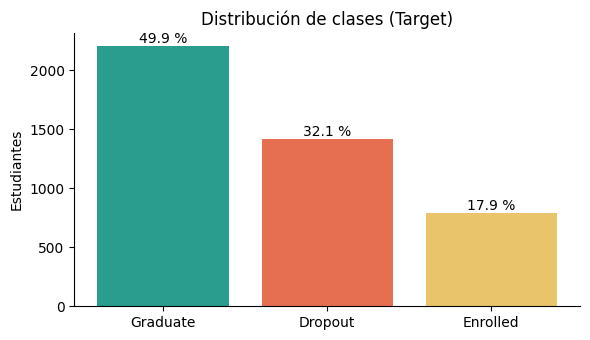

In [7]:
distribucion = (df_raw.groupBy("Target").count()
                .withColumn("porcentaje", F.round(F.col("count") / n_filas * 100, 2))
                .orderBy(F.desc("count")))
dist_pd = distribucion.toPandas()
display(dist_pd)

colores = {"Graduate": "#2a9d8f", "Dropout": "#e76f51", "Enrolled": "#e9c46a"}
fig, ax = plt.subplots(figsize=(6, 3.5))
barras = ax.bar(dist_pd["Target"], dist_pd["count"], color=[colores[c] for c in dist_pd["Target"]])
for b, p in zip(barras, dist_pd["porcentaje"]):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 20, f"{p:.1f} %", ha="center")
ax.set_title("Distribución de clases (Target)")
ax.set_ylabel("Estudiantes")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### 1.6 Análisis del desbalance

- **Clase dominante: Graduate** con 2.209 estudiantes (**≈ 49,9 %**), casi la mitad del total.
- **Dropout** tiene 1.421 estudiantes (**≈ 32,1 %**).
- **Clase minoritaria: Enrolled** con solo 794 estudiantes (**≈ 17,9 %**), unas **2,8 veces menos** que Graduate.

**¿Por qué importa?**
1. **El *accuracy* engaña.** Un modelo "perezoso" que siempre responda *Graduate* acertaría ~50 % sin haber aprendido nada.
2. **Sesgo en el entrenamiento.** Los algoritmos minimizan el error global, así que tienden a favorecer la clase mayoritaria y a ignorar *Enrolled*, que termina con muy bajo *recall*.
3. **Enrolled es la clase más difícil y valiosa.** Es el grupo intermedio (no abandonó, pero va atrasado): su perfil se parece en parte a *Dropout* y en parte a *Graduate*, y es justamente donde una intervención temprana de la universidad puede cambiar el resultado.

**Consecuencia para el proyecto:** se usará el **F1 ponderado** como métrica de selección, **pesos por clase** durante el entrenamiento (tarea 2) y se revisará el **recall por clase** en la evaluación final (tarea 6).

## Tarea 2 · Preprocesamiento

### 2.1 Normalización de los nombres de columnas con expresión regular

**Qué hace:** convierte cada nombre a minúsculas, elimina apóstrofes y reemplaza con la expresión regular `[^a-z0-9]+` todo lo que no sea letra o dígito por `_`; luego colapsa guiones bajos repetidos y quita los de los extremos. Verifica además que no queden dos columnas con el mismo nombre.

**Por qué:** los nombres originales tienen espacios, paréntesis, apóstrofes, `/` y, según la versión del archivo, un **carácter BOM invisible** al inicio del primer nombre o un **tabulador oculto** (`'Daytime/evening attendance\t'` en la versión original). Con esos nombres habría que usar comillas invertidas en Spark SQL y es fácil equivocarse al referenciarlos en el `VectorAssembler` o en la app. La tabla muestra el nombre original con `repr()` para que se vean los caracteres ocultos.

In [8]:
def normalizar_nombre(nombre: str) -> str:
    n = nombre.strip().lower().replace("'", "")
    n = re.sub(r"[^a-z0-9]+", "_", n)      # todo lo que no sea letra o dígito -> "_"
    return re.sub(r"_+", "_", n).strip("_")  # sin "_" repetidos ni en los extremos

nombres_nuevos = [normalizar_nombre(c) for c in df_raw.columns]
assert len(set(nombres_nuevos)) == len(nombres_nuevos), "Dos columnas quedaron con el mismo nombre"

df = df_raw.toDF(*nombres_nuevos)
pd.DataFrame({"original (repr)": [repr(c) for c in df_raw.columns], "normalizado": nombres_nuevos})

,original (repr),normalizado
0,'Marital status',marital_status
1,'Application mode',application_mode
2,'Application order',application_order
3,'Course',course
4,'Daytime/evening attendance',daytime_evening_attendance
5,'Previous qualification',previous_qualification
6,'Nacionality',nacionality
7,"""Mother's qualification""",mothers_qualification
8,"""Father's qualification""",fathers_qualification
9,"""Mother's occupation""",mothers_occupation


### 2.2 Duplicados

**Qué hace:** cuenta las filas, elimina las filas idénticas con `dropDuplicates()` y vuelve a contar.

**Por qué:** un estudiante repetido pesa doble en el entrenamiento y, si una copia cae en entrenamiento y otra en prueba, la evaluación queda inflada (el modelo "ya vio" ese caso).

In [9]:
filas_antes = df.count()
df = df.dropDuplicates().cache()
filas_despues = df.count()
print(f"Filas antes: {filas_antes:,} | después: {filas_despues:,} | duplicados eliminados: {filas_antes - filas_despues}")

Filas antes: 4,424 | después: 4,424 | duplicados eliminados: 0


### 2.3 Valores nulos

**Qué hace:** cuenta los nulos de cada columna (y los `NaN` en las columnas numéricas). Si aparecen, aplica la estrategia: eliminar filas sin `target` (no se pueden usar para entrenar) e imputar las variables numéricas con la **mediana**.

**Por qué:** Spark ML no acepta nulos en el `VectorAssembler`. Se elige la mediana porque es robusta a valores atípicos (por ejemplo, edades de ingreso de hasta 70 años).

In [10]:
tipos_numericos = ("int", "bigint", "double", "float")
expr_nulos = []
for c, t in df.dtypes:
    cond = F.col(c).isNull() | F.isnan(F.col(c)) if t in tipos_numericos else F.col(c).isNull()
    expr_nulos.append(F.sum(cond.cast("int")).alias(c))

nulos = df.select(expr_nulos).toPandas().T.rename(columns={0: "nulos"})
total_nulos = int(nulos["nulos"].sum())
print("Total de valores nulos/NaN en el dataset:", total_nulos)

if total_nulos > 0:
    display(nulos[nulos["nulos"] > 0])
    df = df.dropna(subset=["target"])
    con_nulos = [c for c, t in df.dtypes if t in tipos_numericos and nulos.loc[c, "nulos"] > 0]
    medianas = {c: df.approxQuantile(c, [0.5], 0.01)[0] for c in con_nulos}
    df = df.fillna(medianas).cache()
    print("Imputadas con la mediana:", medianas)
else:
    print("No hay nulos ni NaN: no se requiere imputación.")

Total de valores nulos/NaN en el dataset: 0
No hay nulos ni NaN: no se requiere imputación.


### 2.4 Verificación de los tipos de dato

**Qué hace:** resume los tipos que dedujo `inferSchema` y comprueba que todas las variables predictoras sean numéricas; si alguna hubiera quedado como texto, la convierte a `double`.

**Por qué:** `VectorAssembler` y `StandardScaler` solo trabajan con números. La única columna de texto permitida es `target`, que se indexa aparte. Ojo: que las categóricas sean numéricas **no significa** que deban tratarse como números; eso se resuelve en la tarea 3.

In [11]:
tipos = pd.DataFrame(df.dtypes, columns=["columna", "tipo"])
print("Columnas por tipo:", tipos["tipo"].value_counts().to_dict())

no_numericas = [c for c, t in df.dtypes if t == "string" and c != "target"]
print("Columnas de texto (aparte de target):", no_numericas or "ninguna")
for c in no_numericas:
    df = df.withColumn(c, F.col(c).cast("double"))

print("Valores de target:", [r["target"] for r in df.select("target").distinct().collect()])
tipos.groupby("tipo")["columna"].agg(cantidad="count", columnas=lambda x: ", ".join(x))

Columnas por tipo: {'int': 29, 'double': 5, 'string': 1}
Columnas de texto (aparte de target): ninguna
Valores de target: ['Graduate', 'Enrolled', 'Dropout']


,cantidad,columnas
tipo,,
double,5,"curricular_units_1st_sem_grade, curricular_uni..."
int,29,"marital_status, application_mode, application_..."
string,1,target


### 2.5 Estrategia para el desbalance de clases

Se compararon tres alternativas:

| Estrategia | Ventaja | Desventaja en este caso |
|---|---|---|
| Submuestreo (quitar filas de la mayoritaria) | Rápido | Se perderían ~1.400 estudiantes *Graduate* de un dataset que ya es pequeño. |
| Sobremuestreo (duplicar la minoritaria) | Conserva los datos | Duplica filas de *Enrolled*: favorece el sobreajuste y las copias pueden caer en distintos *folds* de la validación cruzada, inflando el F1. |
| **Pesos por clase (`weightCol`)** ✅ | Usa **todos** los datos sin duplicar nada | Ninguna relevante: `LogisticRegression`, `RandomForestClassifier` y `DecisionTreeClassifier` aceptan `weightCol` de forma nativa. |

**Decisión:**
1. **Pesos por clase** con la fórmula $w_c = \dfrac{N}{K \cdot N_c}$ ($N$ = estudiantes de entrenamiento, $K$ = 3 clases, $N_c$ = estudiantes de la clase $c$). Una clase con pocos estudiantes recibe más peso, de modo que cada clase "aporta" lo mismo al error total. Los pesos se calculan **solo con el conjunto de entrenamiento** para no filtrar información del conjunto de prueba.
2. **F1 ponderado** (`metricName="f1"`) como métrica de selección en la validación cruzada y en la comparación final: combina precisión y recall de cada clase, por lo que un modelo que ignore *Enrolled* sale penalizado, a diferencia del *accuracy*.
3. En la evaluación se reportará además el **recall de *Enrolled*** para verificar que la clase minoritaria realmente se detecta.

### 2.6 Indexación de la etiqueta con `StringIndexer` (fuera del pipeline)

**Qué hace:** convierte `target` (texto) en `label` (0, 1, 2) ordenando por frecuencia descendente y guarda el **orden de las clases** (`labels`).

**Por qué fuera del pipeline:** cuando la app haga una predicción, el estudiante nuevo **no tiene** `target` (es justo lo que queremos predecir). Si el indexador de la etiqueta estuviera dentro del pipeline, el modelo exigiría esa columna al predecir.

**Por qué guardar `labels`:** el modelo devuelve `prediction` como número (0, 1 o 2) y `probability` como un vector en ese mismo orden. La app necesita esta lista para traducir el número al nombre de la clase y asignar cada probabilidad a su clase.

In [12]:
indexador_target = StringIndexer(inputCol="target", outputCol="label",
                                 stringOrderType="frequencyDesc").fit(df)
LABELS = list(indexador_target.labels)
df = indexador_target.transform(df)
with open("labels.json", "w", encoding="utf-8") as f:
    json.dump(LABELS, f, ensure_ascii=False, indent=2)

print("Orden de las clases (índice -> clase):")
for i, clase in enumerate(LABELS):
    print(f"  {i} -> {clase}")
print("Orden guardado en labels.json (también se guardará dentro de modelo_final/)")

Orden de las clases (índice -> clase):
  0 -> Graduate
  1 -> Dropout
  2 -> Enrolled
Orden guardado en labels.json (también se guardará dentro de modelo_final/)


### 2.7 Partición entrenamiento / prueba (80/20, semilla 42) y cálculo de pesos

**Qué hace:** divide los datos con `randomSplit([0.8, 0.2], seed=42)`, calcula los pesos por clase **solo sobre el entrenamiento** y los agrega como columna `peso`. Muestra la distribución de clases en cada conjunto.

**Por qué:** la semilla fija hace que la partición sea **reproducible** (siempre los mismos estudiantes en prueba). Verificar la distribución confirma que ambos conjuntos conservan la proporción original de clases. El conjunto de prueba **no se toca** hasta la tarea 6.

In [13]:
train, test = df.randomSplit([0.8, 0.2], seed=42)

N_TRAIN, K = train.count(), len(LABELS)
conteo_train = {int(r["label"]): r["count"] for r in train.groupBy("label").count().collect()}
PESOS = {lab: N_TRAIN / (K * n) for lab, n in conteo_train.items()}

expr_peso = None
for lab, w in PESOS.items():
    expr_peso = (F.when(F.col("label") == lab, F.lit(w)) if expr_peso is None
                 else expr_peso.when(F.col("label") == lab, F.lit(w)))
train = train.withColumn("peso", expr_peso).cache()
test = test.cache()

conteo_test = {int(r["label"]): r["count"] for r in test.groupBy("label").count().collect()}
N_TEST = test.count()
resumen_particion = pd.DataFrame({
    "clase": LABELS,
    "train (n)": [conteo_train[i] for i in range(K)],
    "train (%)": [round(conteo_train[i] / N_TRAIN * 100, 1) for i in range(K)],
    "test (n)": [conteo_test[i] for i in range(K)],
    "test (%)": [round(conteo_test[i] / N_TEST * 100, 1) for i in range(K)],
    "peso": [round(PESOS[i], 3) for i in range(K)],
})
print(f"Entrenamiento: {N_TRAIN:,} filas | Prueba: {N_TEST:,} filas")
resumen_particion

Entrenamiento: 3,583 filas | Prueba: 841 filas


,clase,train (n),train (%),test (n),test (%),peso
0,Graduate,1766,49.3,443,52.7,0.676
1,Dropout,1167,32.6,254,30.2,1.023
2,Enrolled,650,18.1,144,17.1,1.837


## Tarea 3 · Ingeniería de características

### 3.1 Variables derivadas con sentido académico

**Qué hace:** define la función `agregar_variables_derivadas(df)` que crea 5 variables nuevas y la aplica a entrenamiento y prueba. **Esta misma función se copiará en la app de Streamlit** (punto 7c) para que los datos del formulario se transformen igual que en el entrenamiento.

| Variable | Fórmula | Qué mide |
|---|---|---|
| `tasa_aprob_1sem` | aprobadas 1.er sem / inscritas 1.er sem | Qué proporción de lo que inscribió logró aprobar en el primer semestre. |
| `tasa_aprob_2sem` | aprobadas 2.º sem / inscritas 2.º sem | Lo mismo en el segundo semestre. |
| `variacion_nota` | nota 2.º sem − nota 1.er sem | Si el rendimiento **mejora o empeora** entre semestres. Una caída fuerte es una señal típica de abandono. |
| `variacion_tasa_aprob` | tasa 2.º sem − tasa 1.er sem | Si el estudiante aprueba proporcionalmente más o menos que antes (tendencia de avance). |
| `eficiencia_evaluaciones` | aprobadas (año) / evaluaciones presentadas (año) | Cuántas de las evaluaciones que presentó terminaron en materia aprobada (efectividad). |

**Control de la división por cero:** 180 estudiantes tienen 0 materias inscritas y cientos tienen 0 evaluaciones. Cada división usa `F.when(denominador > 0, ...).otherwise(0.0)`: si no inscribió nada, su tasa es 0 en lugar de un error o un valor nulo. Son transformaciones fila a fila, por lo que aplicarlas por separado a entrenamiento y prueba no filtra información.

In [14]:
COLUMNAS_BASE_DERIVADAS = [
    "curricular_units_1st_sem_enrolled", "curricular_units_1st_sem_approved",
    "curricular_units_1st_sem_evaluations", "curricular_units_1st_sem_grade",
    "curricular_units_2nd_sem_enrolled", "curricular_units_2nd_sem_approved",
    "curricular_units_2nd_sem_evaluations", "curricular_units_2nd_sem_grade",
]
VARIABLES_DERIVADAS = ["tasa_aprob_1sem", "tasa_aprob_2sem", "variacion_nota",
                       "variacion_tasa_aprob", "eficiencia_evaluaciones"]


def division_segura(numerador, denominador):
    # Devuelve numerador/denominador, o 0.0 cuando el denominador es 0 (control de división por cero)
    return F.when(denominador > 0, numerador / denominador).otherwise(F.lit(0.0))


def agregar_variables_derivadas(df):
    c = F.col
    df = df.withColumn("tasa_aprob_1sem", division_segura(c("curricular_units_1st_sem_approved"),
                                                          c("curricular_units_1st_sem_enrolled")))
    df = df.withColumn("tasa_aprob_2sem", division_segura(c("curricular_units_2nd_sem_approved"),
                                                          c("curricular_units_2nd_sem_enrolled")))
    df = df.withColumn("variacion_nota", (c("curricular_units_2nd_sem_grade")
                                          - c("curricular_units_1st_sem_grade")).cast("double"))
    df = df.withColumn("variacion_tasa_aprob", c("tasa_aprob_2sem") - c("tasa_aprob_1sem"))
    df = df.withColumn("eficiencia_evaluaciones", division_segura(
        c("curricular_units_1st_sem_approved") + c("curricular_units_2nd_sem_approved"),
        c("curricular_units_1st_sem_evaluations") + c("curricular_units_2nd_sem_evaluations")))
    return df


train = agregar_variables_derivadas(train).cache()
test = agregar_variables_derivadas(test).cache()

nulos_derivadas = train.select([F.sum(F.col(v).isNull().cast("int")).alias(v) for v in VARIABLES_DERIVADAS]).first()
print("Nulos en variables derivadas (train):", nulos_derivadas.asDict())
train.select(VARIABLES_DERIVADAS).describe().toPandas().set_index("summary").T

Nulos en variables derivadas (train): {'tasa_aprob_1sem': 0, 'tasa_aprob_2sem': 0, 'variacion_nota': 0, 'variacion_tasa_aprob': 0, 'eficiencia_evaluaciones': 0}


summary,count,mean,stddev,min,max
tasa_aprob_1sem,3583,0.6993527098048626,0.36415171407982544,0.0,1.0
tasa_aprob_2sem,3583,0.6603882297784233,0.3827490441126236,0.0,1.0
variacion_nota,3583,-0.4385548011058349,2.9185430934202663,-16.142857142857142,16.0
variacion_tasa_aprob,3583,-0.0389644800264393,0.1915043049326763,-1.0,1.0
eficiencia_evaluaciones,3583,0.5378360564496313,0.33666210394296014,0.0,1.0


### 3.2 ¿Las variables derivadas separan las clases?

**Qué hace:** calcula el promedio de cada variable derivada por clase (solo con entrenamiento).

**Por qué:** es una comprobación rápida de que las variables nuevas tienen sentido: si los promedios son muy distintos entre *Dropout*, *Enrolled* y *Graduate*, la variable aporta información para clasificar.

In [15]:
promedios = (train.groupBy("target")
             .agg(*[F.round(F.avg(v), 3).alias(v) for v in VARIABLES_DERIVADAS])
             .toPandas().set_index("target").loc[["Dropout", "Enrolled", "Graduate"]])
promedios

,tasa_aprob_1sem,tasa_aprob_2sem,variacion_nota,variacion_tasa_aprob,eficiencia_evaluaciones
target,,,,,
Dropout,0.392,0.299,-1.399,-0.093,0.246
Enrolled,0.688,0.650,-0.020,-0.038,0.449
Graduate,0.907,0.903,0.042,-0.004,0.763


### Lectura de las variables derivadas

- Las tres clases quedan claramente separadas: la **tasa de aprobación del 2.º semestre** es 0,30 en *Dropout*, 0,65 en *Enrolled* y 0,90 en *Graduate*; la **eficiencia en evaluaciones** sigue el mismo patrón (0,25 → 0,45 → 0,76).
- La **variación de la nota** es fuertemente negativa en *Dropout* (−1,40 puntos: el rendimiento se desploma en el 2.º semestre), casi nula en *Enrolled* (−0,02) y levemente positiva en *Graduate* (+0,04).
- *Enrolled* queda **en medio** en todas las variables, lo que confirma por qué es la clase más difícil de separar: comparte rasgos con las otras dos.

### 3.3 Separación de variables categóricas y numéricas

**Qué hace:** clasifica cada columna como categórica o numérica.

**Por qué:** muchas variables vienen como números, pero son **códigos** sin orden ni magnitud: `course = 9254` no es "más" que `course = 171`, y la ocupación 194 no es "mayor" que la 90. Si se dejaran como numéricas, los modelos (en especial la regresión logística) interpretarían distancias que no existen. Por eso se codifican con *one-hot*.
- **Categóricas (nominales):** estado civil, modalidad de ingreso, carrera, jornada, formación previa, nacionalidad, formación y ocupación de los padres, y los indicadores sí/no (desplazado, necesidades especiales, deudor, matrícula al día, género, becado, internacional).
- **Numéricas:** orden de preferencia de la carrera (0 = primera opción, es ordinal), notas previas y de admisión, edad, unidades curriculares de cada semestre, indicadores macroeconómicos y las 5 variables derivadas.

Las listas se filtran por las columnas presentes, para que el notebook funcione con cualquiera de las dos versiones del dataset.

In [16]:
CATEGORICAS_CANDIDATAS = [
    "marital_status", "application_mode", "course", "daytime_evening_attendance",
    "previous_qualification", "nacionality", "mothers_qualification", "fathers_qualification",
    "mothers_occupation", "fathers_occupation", "displaced", "educational_special_needs",
    "debtor", "tuition_fees_up_to_date", "gender", "scholarship_holder", "international",
]
EXCLUIR = {"target", "label", "peso"}

CATEGORICAS = [c for c in CATEGORICAS_CANDIDATAS if c in train.columns]
NUMERICAS = [c for c in train.columns if c not in CATEGORICAS and c not in EXCLUIR]

print(f"Categóricas ({len(CATEGORICAS)}):", CATEGORICAS)
print(f"\nNuméricas ({len(NUMERICAS)}):", NUMERICAS)

Categóricas (17): ['marital_status', 'application_mode', 'course', 'daytime_evening_attendance', 'previous_qualification', 'nacionality', 'mothers_qualification', 'fathers_qualification', 'mothers_occupation', 'fathers_occupation', 'displaced', 'educational_special_needs', 'debtor', 'tuition_fees_up_to_date', 'gender', 'scholarship_holder', 'international']

Numéricas (22): ['application_order', 'age_at_enrollment', 'curricular_units_1st_sem_credited', 'curricular_units_1st_sem_enrolled', 'curricular_units_1st_sem_evaluations', 'curricular_units_1st_sem_approved', 'curricular_units_1st_sem_grade', 'curricular_units_1st_sem_without_evaluations', 'curricular_units_2nd_sem_credited', 'curricular_units_2nd_sem_enrolled', 'curricular_units_2nd_sem_evaluations', 'curricular_units_2nd_sem_approved', 'curricular_units_2nd_sem_grade', 'curricular_units_2nd_sem_without_evaluations', 'unemployment_rate', 'inflation_rate', 'gdp', 'tasa_aprob_1sem', 'tasa_aprob_2sem', 'variacion_nota', 'variacion_t

### 3.4 Etapas de transformación del Pipeline

**Qué hace:** define la función `construir_pipeline(clasificador, categoricas, numericas)` que arma **todo el preprocesamiento dentro del Pipeline**:

1. **`StringIndexer(handleInvalid="keep")`**: convierte cada código categórico en un índice. Con `"keep"`, si la app recibe un código que no existía en el entrenamiento (por ejemplo, una carrera nueva), se manda a una categoría "desconocida" en lugar de romper la predicción.
2. **`OneHotEncoder`**: transforma cada índice en un vector binario (una posición por categoría), eliminando el falso orden entre códigos.
3. **`VectorAssembler`**: une las variables numéricas y los vectores *one-hot* en una sola columna `features_sin_escalar`.
4. **`StandardScaler`** (`withStd=True`, `withMean=False`): escala cada característica a desviación estándar 1. Es indispensable para la regresión logística con regularización (si no, las variables con números grandes, como la nota de admisión, dominarían la penalización). `withMean=False` conserva los vectores dispersos del *one-hot*.
5. **Clasificador** (la última etapa cambia según el modelo).

**Por qué todo dentro del Pipeline:** al guardar el `PipelineModel`, se guardan también los índices, el codificador y las medias/desviaciones aprendidas. La app solo entrega los datos crudos y el pipeline aplica exactamente las mismas transformaciones que en el entrenamiento.

In [17]:
def construir_pipeline(clasificador, categoricas, numericas):
    idx_cols = [f"{c}_idx" for c in categoricas]
    ohe_cols = [f"{c}_ohe" for c in categoricas]
    indexador = StringIndexer(inputCols=categoricas, outputCols=idx_cols, handleInvalid="keep")
    codificador = OneHotEncoder(inputCols=idx_cols, outputCols=ohe_cols, handleInvalid="keep")
    ensamblador = VectorAssembler(inputCols=numericas + ohe_cols, outputCol="features_sin_escalar")
    escalador = StandardScaler(inputCol="features_sin_escalar", outputCol="features",
                               withStd=True, withMean=False)
    return Pipeline(stages=[indexador, codificador, ensamblador, escalador, clasificador])

print("Función construir_pipeline definida: StringIndexer -> OneHotEncoder -> VectorAssembler -> StandardScaler -> clasificador")

Función construir_pipeline definida: StringIndexer -> OneHotEncoder -> VectorAssembler -> StandardScaler -> clasificador


### 3.5 Selección de variables con `featureImportances` del Random Forest

**Qué hace:** entrena un Random Forest preliminar (100 árboles, profundidad 8, semilla 42) **solo con el entrenamiento**, extrae `featureImportances` y las asocia al nombre de cada característica usando los metadatos del `VectorAssembler`. Como cada categórica se convierte en varias columnas *one-hot*, se **suman** sus importancias para obtener la importancia de la variable original.

**Por qué este método y no `ChiSqSelector`:** `ChiSqSelector` está pensado para características discretas y la mayoría de las nuestras son continuas (notas, tasas, indicadores macroeconómicos); además, en Spark 3.1+ fue reemplazado por `UnivariateFeatureSelector`. Las importancias del Random Forest capturan relaciones no lineales e interacciones y se interpretan directamente: qué tanto reduce la impureza cada variable.

Random Forest preliminar entrenado en 22.5 s
Vector de características: 266 posiciones -> 39 variables originales


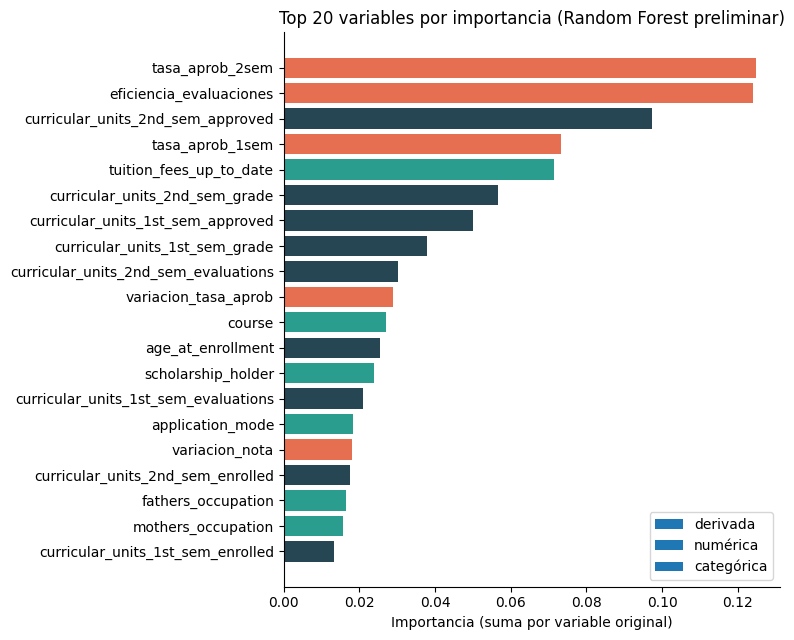

,variable,importancia,tipo,acumulada
0,tasa_aprob_2sem,0.1249,derivada,0.1249
1,eficiencia_evaluaciones,0.1240,derivada,0.2489
2,curricular_units_2nd_sem_approved,0.0972,numérica,0.3461
3,tasa_aprob_1sem,0.0733,derivada,0.4194
4,tuition_fees_up_to_date,0.0715,categórica,0.4909
5,curricular_units_2nd_sem_grade,0.0567,numérica,0.5476
6,curricular_units_1st_sem_approved,0.0499,numérica,0.5975
7,curricular_units_1st_sem_grade,0.0380,numérica,0.6355
8,curricular_units_2nd_sem_evaluations,0.0301,numérica,0.6655
9,variacion_tasa_aprob,0.0288,derivada,0.6943


In [18]:
t0 = time.time()
rf_preliminar = RandomForestClassifier(labelCol="label", featuresCol="features", weightCol="peso",
                                       numTrees=100, maxDepth=8, seed=42)
modelo_preliminar = construir_pipeline(rf_preliminar, CATEGORICAS, NUMERICAS).fit(train)
print(f"Random Forest preliminar entrenado en {time.time() - t0:.1f} s")

# Nombres de cada posición del vector de características (metadatos del VectorAssembler)
meta = modelo_preliminar.transform(train.limit(1)).schema["features_sin_escalar"].metadata["ml_attr"]["attrs"]
nombres_vector = {a["idx"]: a["name"] for grupo in meta.values() for a in grupo}
importancias = modelo_preliminar.stages[-1].featureImportances.toArray()


def variable_original(nombre_vector):
    for c in CATEGORICAS:
        if nombre_vector.startswith(f"{c}_ohe"):
            return c
    return nombre_vector


imp_pd = pd.DataFrame({"caracteristica": [nombres_vector[i] for i in range(len(importancias))],
                       "importancia": importancias})
imp_pd["variable"] = imp_pd["caracteristica"].map(variable_original)
imp_var = (imp_pd.groupby("variable", as_index=False)["importancia"].sum()
           .sort_values("importancia", ascending=False).reset_index(drop=True))
imp_var["tipo"] = imp_var["variable"].map(lambda v: "derivada" if v in VARIABLES_DERIVADAS
                                          else ("categórica" if v in CATEGORICAS else "numérica"))
imp_var["acumulada"] = imp_var["importancia"].cumsum()

print(f"Vector de características: {len(importancias)} posiciones -> {len(imp_var)} variables originales")
top = imp_var.head(20).iloc[::-1]
color_tipo = {"derivada": "#e76f51", "numérica": "#264653", "categórica": "#2a9d8f"}
fig, ax = plt.subplots(figsize=(8, 6.5))
ax.barh(top["variable"], top["importancia"], color=[color_tipo[t] for t in top["tipo"]])
ax.set_title("Top 20 variables por importancia (Random Forest preliminar)")
ax.set_xlabel("Importancia (suma por variable original)")
for t, col in color_tipo.items():
    ax.barh([], [], color=col, label=t)
ax.legend(loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()
imp_var.round(4)

### 3.6 Regla de selección y verificación con validación cruzada

**Qué hace:** conserva solo las variables con importancia **≥ 1 %** y compara, con validación cruzada de 3 *folds* sobre el entrenamiento, el F1 del mismo Random Forest usando **todas** las variables frente a usar **solo las seleccionadas**.

**Por qué:** una variable con menos del 1 % de importancia casi no participa en las decisiones del bosque; mantenerla agrega ruido, columnas *one-hot* (más dimensiones para la regresión logística) y campos innecesarios en el formulario de la app. La comparación por validación cruzada (sin tocar el conjunto de prueba) demuestra si quitarlas afecta el desempeño.

**Criterio de decisión (parsimonia):** si el F1 con las variables seleccionadas no cae más de 0,005 respecto a usar todas, se prefiere el modelo más simple (`USAR_SELECCION = True`).

In [19]:
UMBRAL_IMPORTANCIA = 0.01
seleccionadas = set(imp_var.loc[imp_var["importancia"] >= UMBRAL_IMPORTANCIA, "variable"])
descartadas = imp_var.loc[imp_var["importancia"] < UMBRAL_IMPORTANCIA, ["variable", "importancia"]]

CAT_SEL = [c for c in CATEGORICAS if c in seleccionadas]
NUM_SEL = [c for c in NUMERICAS if c in seleccionadas]

evaluador_f1 = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="f1")


def f1_cv(categoricas, numericas):
    rf = RandomForestClassifier(labelCol="label", featuresCol="features", weightCol="peso",
                                numTrees=100, maxDepth=8, seed=42)
    cv = CrossValidator(estimator=construir_pipeline(rf, categoricas, numericas),
                        estimatorParamMaps=ParamGridBuilder().build(),
                        evaluator=evaluador_f1, numFolds=3, seed=42, parallelism=2)
    return cv.fit(train).avgMetrics[0]


t0 = time.time()
f1_todas = f1_cv(CATEGORICAS, NUMERICAS)
f1_sel = f1_cv(CAT_SEL, NUM_SEL)
print(f"Validación cruzada en {time.time() - t0:.1f} s")
print(f"F1 (CV) con todas las variables     ({len(CATEGORICAS) + len(NUMERICAS)}): {f1_todas:.4f}")
print(f"F1 (CV) con variables seleccionadas ({len(CAT_SEL) + len(NUM_SEL)}): {f1_sel:.4f}")
USAR_SELECCION = f1_sel >= f1_todas - 0.005   # parsimonia: aceptar si el F1 no cae más de 0,005
print("¿Se usan solo las variables seleccionadas?:", USAR_SELECCION)
print(f"\nDescartadas ({len(descartadas)}):")
display(descartadas.round(4))

Validación cruzada en 96.6 s
F1 (CV) con todas las variables     (39): 0.7584
F1 (CV) con variables seleccionadas (23): 0.7542
¿Se usan solo las variables seleccionadas?: True

Descartadas (16):


,variable,importancia
23,gdp,0.0082
24,previous_qualification,0.0080
25,gender,0.0078
26,unemployment_rate,0.0076
27,inflation_rate,0.0063
28,marital_status,0.0055
29,curricular_units_1st_sem_credited,0.0052
30,application_order,0.0045
31,curricular_units_2nd_sem_credited,0.0040
32,displaced,0.0036


### Decisión sobre la selección de variables

- Las **5 variables derivadas** superan el umbral: `tasa_aprob_2sem` es la **n.º 1** del modelo, `eficiencia_evaluaciones` la n.º 2 y `tasa_aprob_1sem` la n.º 4. Esto valida la ingeniería de características de la tarea 3.1.
- Junto a ellas dominan el rendimiento académico (aprobadas y notas por semestre) y estar **al día con la matrícula** (`tuition_fees_up_to_date`, n.º 5), un factor socioeconómico claro.
- Se descartan 16 variables con importancia < 1 %: los indicadores macroeconómicos (PIB, desempleo, inflación), que son iguales para todos los estudiantes que ingresaron el mismo año y casi no distinguen entre individuos; variables donde casi todos tienen el mismo valor (`international`, `educational_special_needs`), y los créditos convalidados / materias sin evaluar.
- Con las 23 variables seleccionadas el F1 en validación cruzada fue **0,7542** frente a **0,7584** con las 39: una diferencia de apenas **0,0042**, menor que la variación entre folds y dentro de la tolerancia definida. Se elige el modelo más simple: **menos ruido, menos dimensiones y un formulario más corto en la app** (18 campos en lugar de 34).

### 3.7 Listas finales de variables del modelo

**Qué hace:** fija las listas de variables categóricas y numéricas que usarán los tres modelos y muestra el total.

**Por qué:** las tres comparaciones de la sección B deben hacerse con **las mismas variables**, para que la diferencia de desempeño se deba al algoritmo y no a los datos de entrada.

In [20]:
CAT_FINAL = CAT_SEL if USAR_SELECCION else CATEGORICAS
NUM_FINAL = NUM_SEL if USAR_SELECCION else NUMERICAS
print("Usar selección:", USAR_SELECCION)
print(f"Categóricas finales ({len(CAT_FINAL)}):", CAT_FINAL)
print(f"Numéricas finales   ({len(NUM_FINAL)}):", NUM_FINAL)

Usar selección: True
Categóricas finales (9): ['application_mode', 'course', 'mothers_qualification', 'fathers_qualification', 'mothers_occupation', 'fathers_occupation', 'debtor', 'tuition_fees_up_to_date', 'scholarship_holder']
Numéricas finales   (14): ['age_at_enrollment', 'curricular_units_1st_sem_enrolled', 'curricular_units_1st_sem_evaluations', 'curricular_units_1st_sem_approved', 'curricular_units_1st_sem_grade', 'curricular_units_2nd_sem_enrolled', 'curricular_units_2nd_sem_evaluations', 'curricular_units_2nd_sem_approved', 'curricular_units_2nd_sem_grade', 'tasa_aprob_1sem', 'tasa_aprob_2sem', 'variacion_nota', 'variacion_tasa_aprob', 'eficiencia_evaluaciones']


---
# Sección B · Pipelines, hiperparametrización y validación cruzada
## Tarea 4 · Los tres modelos dentro de un Pipeline completo

**Qué hace:** crea los tres clasificadores multiclase de Spark ML y los envuelve, cada uno, en el Pipeline completo (indexado → codificación → ensamblado → escalado → clasificador). Luego entrena cada pipeline con sus hiperparámetros por defecto como **línea base**.

**Configuración común:**
- `labelCol="label"`, `featuresCol="features"` y **`weightCol="peso"`** (estrategia de desbalance de la tarea 2).
- **`LogisticRegression(family="multinomial")`**: un solo modelo *softmax* para las 3 clases (en lugar de 3 modelos uno-contra-todos).
- **`RandomForestClassifier(seed=42)`** y **`DecisionTreeClassifier(seed=42)`**: semilla fija para que los resultados sean reproducibles.

**Por qué una línea base:** permite medir después cuánto aportó la hiperparametrización.

In [21]:
def crear_clasificador(nombre, con_pesos=True):
    comunes = dict(labelCol="label", featuresCol="features")
    if con_pesos:
        comunes["weightCol"] = "peso"
    if nombre == "LogisticRegression":
        return LogisticRegression(family="multinomial", maxIter=100, **comunes)
    if nombre == "RandomForest":
        return RandomForestClassifier(seed=42, **comunes)
    if nombre == "DecisionTree":
        return DecisionTreeClassifier(seed=42, **comunes)
    raise ValueError(nombre)


NOMBRES_MODELOS = ["LogisticRegression", "RandomForest", "DecisionTree"]
clasificadores = {n: crear_clasificador(n) for n in NOMBRES_MODELOS}
pipelines = {n: construir_pipeline(clf, CAT_FINAL, NUM_FINAL) for n, clf in clasificadores.items()}

modelos_base = {}
for nombre, pipe in pipelines.items():
    t0 = time.time()
    modelos_base[nombre] = pipe.fit(train)
    etapas = " -> ".join(type(s).__name__ for s in modelos_base[nombre].stages)
    print(f"{nombre:<20} entrenado en {time.time() - t0:5.1f} s | {etapas}")

LogisticRegression   entrenado en  16.1 s | StringIndexerModel -> OneHotEncoderModel -> VectorAssembler -> StandardScalerModel -> LogisticRegressionModel
RandomForest         entrenado en   5.0 s | StringIndexerModel -> OneHotEncoderModel -> VectorAssembler -> StandardScalerModel -> RandomForestClassificationModel
DecisionTree         entrenado en   3.7 s | StringIndexerModel -> OneHotEncoderModel -> VectorAssembler -> StandardScalerModel -> DecisionTreeClassificationModel


## Tarea 5 · Hiperparametrización con `ParamGridBuilder` y `CrossValidator`

**Qué hace:** para cada modelo construye una grilla de **2 hiperparámetros × 2 valores** con `ParamGridBuilder(...).build()` y la evalúa con `CrossValidator` de **3 folds**, usando el **F1 ponderado** como evaluador. Cada modelo prueba 4 combinaciones × 3 folds = 12 entrenamientos, más el reentrenamiento final con la mejor combinación sobre todo el conjunto de entrenamiento.

| Modelo | Hiperparámetro 1 | Hiperparámetro 2 | Qué controla |
|---|---|---|---|
| LogisticRegression | `regParam` ∈ {0.01, 0.1} | `elasticNetParam` ∈ {0.0, 0.5} | Fuerza de la regularización y mezcla L2 (0.0) / L1+L2 (0.5). |
| RandomForest | `numTrees` ∈ {50, 100} | `maxDepth` ∈ {5, 10} | Cantidad de árboles y complejidad de cada árbol. |
| DecisionTree | `maxDepth` ∈ {5, 10} | `minInstancesPerNode` ∈ {1, 10} | Profundidad del árbol y mínimo de estudiantes por hoja (poda). |

**Por qué 3 folds y 2 hiperparámetros:** es el equilibrio recomendado entre robustez de la estimación y tiempo de entrenamiento en Colab. `seed=42` fija la asignación de folds y `parallelism=2` entrena dos combinaciones a la vez (Colab tiene 2 núcleos).

La función `ejecutar_cv` entrena la validación cruzada y muestra el F1 promedio (± desviación entre folds) de **cada combinación**.

In [22]:
grillas = {
    "LogisticRegression": (ParamGridBuilder()
                           .addGrid(clasificadores["LogisticRegression"].regParam, [0.01, 0.1])
                           .addGrid(clasificadores["LogisticRegression"].elasticNetParam, [0.0, 0.5])
                           .build()),
    "RandomForest": (ParamGridBuilder()
                     .addGrid(clasificadores["RandomForest"].numTrees, [50, 100])
                     .addGrid(clasificadores["RandomForest"].maxDepth, [5, 10])
                     .build()),
    "DecisionTree": (ParamGridBuilder()
                     .addGrid(clasificadores["DecisionTree"].maxDepth, [5, 10])
                     .addGrid(clasificadores["DecisionTree"].minInstancesPerNode, [1, 10])
                     .build()),
}

modelos_cv, tiempos_cv = {}, {}


def ejecutar_cv(nombre):
    cv = CrossValidator(estimator=pipelines[nombre], estimatorParamMaps=grillas[nombre],
                        evaluator=evaluador_f1, numFolds=3, seed=42, parallelism=2)
    t0 = time.time()
    modelo = cv.fit(train)
    tiempos_cv[nombre] = time.time() - t0
    modelos_cv[nombre] = modelo

    filas = []
    for params, media, desv in zip(grillas[nombre], modelo.avgMetrics, modelo.stdMetrics):
        fila = {p.name: v for p, v in params.items()}
        fila.update({"F1 promedio (CV)": round(media, 4), "desv. estándar": round(desv, 4)})
        filas.append(fila)
    tabla = pd.DataFrame(filas).sort_values("F1 promedio (CV)", ascending=False).reset_index(drop=True)
    print(f"{nombre}: validación cruzada completada en {tiempos_cv[nombre]:.1f} s "
          f"({len(grillas[nombre])} combinaciones x 3 folds)")
    return tabla

print("Grillas construidas:", {n: len(g) for n, g in grillas.items()})

Grillas construidas: {'LogisticRegression': 4, 'RandomForest': 4, 'DecisionTree': 4}


### 5.1 Validación cruzada · Regresión logística multinomial

**Qué hace:** ejecuta la búsqueda de `regParam` y `elasticNetParam`.

**Por qué:** `regParam` penaliza coeficientes grandes (evita sobreajuste) y `elasticNetParam` decide si la penalización es solo L2 (reduce coeficientes) o mezcla L1 (además puede llevar coeficientes a cero, una selección de variables implícita).

In [23]:
ejecutar_cv("LogisticRegression")

LogisticRegression: validación cruzada completada en 103.0 s (4 combinaciones x 3 folds)


,regParam,elasticNetParam,F1 promedio (CV),desv. estándar
0,0.01,0.5,0.7571,0.0078
1,0.10,0.0,0.7528,0.0036
2,0.01,0.0,0.7514,0.0055
3,0.10,0.5,0.7472,0.0174


### 5.2 Validación cruzada · Random Forest

**Qué hace:** ejecuta la búsqueda de `numTrees` y `maxDepth`.

**Por qué:** más árboles estabilizan el voto (menos varianza) y mayor profundidad permite capturar interacciones más complejas, con riesgo de sobreajuste.

In [24]:
ejecutar_cv("RandomForest")

RandomForest: validación cruzada completada en 86.9 s (4 combinaciones x 3 folds)


,numTrees,maxDepth,F1 promedio (CV),desv. estándar
0,50,10,0.7627,0.0179
1,100,10,0.7617,0.0178
2,100,5,0.7512,0.0142
3,50,5,0.7485,0.0155


### 5.3 Validación cruzada · Árbol de decisión

**Qué hace:** ejecuta la búsqueda de `maxDepth` y `minInstancesPerNode`.

**Por qué:** un solo árbol sobreajusta con facilidad; limitar la profundidad y exigir un mínimo de estudiantes por nodo funciona como poda.

In [25]:
ejecutar_cv("DecisionTree")

DecisionTree: validación cruzada completada en 39.2 s (4 combinaciones x 3 folds)


,maxDepth,minInstancesPerNode,F1 promedio (CV),desv. estándar
0,5,1,0.7275,0.0167
1,5,10,0.7260,0.0188
2,10,10,0.7105,0.0079
3,10,1,0.7102,0.0148


### 5.4 Mejores hiperparámetros de cada modelo

**Qué hace:** extrae de cada `CrossValidatorModel` la combinación ganadora, leyendo los parámetros directamente de la última etapa de `bestModel`, junto con su F1 promedio en validación cruzada y el tiempo de búsqueda.

**Por qué:** confirma qué configuración se reentrenó con todo el conjunto de entrenamiento y será la que se evalúe en la tarea 6.

In [26]:
filas = []
for nombre in NOMBRES_MODELOS:
    modelo = modelos_cv[nombre]
    clf_final = modelo.bestModel.stages[-1]
    mejores = {p.name: clf_final.getOrDefault(clf_final.getParam(p.name)) for p in grillas[nombre][0]}
    filas.append({"modelo": nombre,
                  "mejores hiperparámetros": ", ".join(f"{k}={v}" for k, v in mejores.items()),
                  "F1 promedio (CV)": round(max(modelo.avgMetrics), 4),
                  "tiempo CV (s)": round(tiempos_cv[nombre], 1)})
mejores_hp = pd.DataFrame(filas)
mejores_hp

,modelo,mejores hiperparámetros,F1 promedio (CV),tiempo CV (s)
0,LogisticRegression,"regParam=0.01, elasticNetParam=0.5",0.7571,103.0
1,RandomForest,"numTrees=50, maxDepth=10",0.7627,86.9
2,DecisionTree,"maxDepth=5, minInstancesPerNode=1",0.7275,39.2


### Análisis de los hiperparámetros

- **Regresión logística (`regParam=0.01`, `elasticNetParam=0.5`):** gana la regularización **suave** con mezcla L1+L2 (0,7571). La parte L1 lleva a cero coeficientes de categorías *one-hot* poco útiles (selección de variables adicional). Con regularización fuerte y L1 (`0.1` + `0.5`) el modelo queda demasiado restringido y cae a 0,7472.
- **Random Forest (`numTrees=50`, `maxDepth=10`):** la **profundidad** es lo que más pesa: pasar de 5 a 10 sube el F1 ~0,011, mientras que pasar de 50 a 100 árboles prácticamente no cambia nada (0,7627 vs 0,7617). Los árboles necesitan profundidad para capturar interacciones; con 50 árboles el voto ya es estable, así que más árboles solo aumentan el tiempo.
- **Árbol de decisión (`maxDepth=5`, `minInstancesPerNode=1`):** ocurre lo contrario: el árbol profundo (10) **sobreajusta** y baja a ~0,710. Un solo árbol no tiene el promedio de muchos árboles que lo proteja, así que limitar la profundidad funciona mejor. `minInstancesPerNode` casi no influye con profundidad 5 porque las hojas ya son grandes.
- En validación cruzada el **Random Forest es el mejor (0,7627)**, seguido de la regresión logística (0,7571) y del árbol de decisión (0,7275).

---
# Sección C · Evaluación, selección y guardado del mejor modelo
## Tarea 6 · Evaluación sobre el conjunto de prueba

### 6.1 Métricas de los tres modelos

**Qué hace:** aplica el mejor modelo de cada validación cruzada al **conjunto de prueba** (nunca al de entrenamiento) y calcula *accuracy*, F1 ponderado, precisión ponderada y recall ponderado. Agrega el **recall y el F1 de la clase *Enrolled*** (la minoritaria) y, como referencia, el F1 de la línea base sin ajustar.

**Por qué el conjunto de prueba:** son estudiantes que ningún modelo vio durante el entrenamiento ni la validación cruzada, así que estas métricas estiman el desempeño real con estudiantes nuevos.

In [27]:
IDX_ENROLLED = LABELS.index("Enrolled")


def evaluar(predicciones):
    ev = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction")
    return {
        "accuracy": ev.evaluate(predicciones, {ev.metricName: "accuracy"}),
        "f1": ev.evaluate(predicciones, {ev.metricName: "f1"}),
        "precision_ponderada": ev.evaluate(predicciones, {ev.metricName: "weightedPrecision"}),
        "recall_ponderado": ev.evaluate(predicciones, {ev.metricName: "weightedRecall"}),
        "recall_enrolled": ev.evaluate(predicciones, {ev.metricName: "recallByLabel", ev.metricLabel: IDX_ENROLLED}),
        "f1_enrolled": ev.evaluate(predicciones, {ev.metricName: "fMeasureByLabel", ev.metricLabel: IDX_ENROLLED}),
    }


predicciones_test, resultados = {}, []
for nombre in NOMBRES_MODELOS:
    predicciones_test[nombre] = modelos_cv[nombre].bestModel.transform(test).cache()
    m = evaluar(predicciones_test[nombre])
    m_base = evaluar(modelos_base[nombre].transform(test))
    resultados.append({"modelo": nombre, **m, "f1_linea_base": m_base["f1"]})

comparacion = (pd.DataFrame(resultados).set_index("modelo")
               .sort_values("f1", ascending=False).round(4))
comparacion

,accuracy,f1,precision_ponderada,recall_ponderado,recall_enrolled,f1_enrolled,f1_linea_base
modelo,,,,,,,
RandomForest,0.7396,0.7536,0.7795,0.7396,0.6181,0.4904,0.7239
LogisticRegression,0.7325,0.7435,0.7614,0.7325,0.5625,0.4709,0.7504
DecisionTree,0.7075,0.7267,0.7625,0.7075,0.5417,0.4138,0.7267


### 6.2 Gráfico comparativo

**Qué hace:** grafica las cuatro métricas principales y el recall de *Enrolled* de los tres modelos.

**Por qué:** facilita ver de un vistazo cuál modelo domina y si alguno sacrifica la clase minoritaria a cambio de *accuracy*.

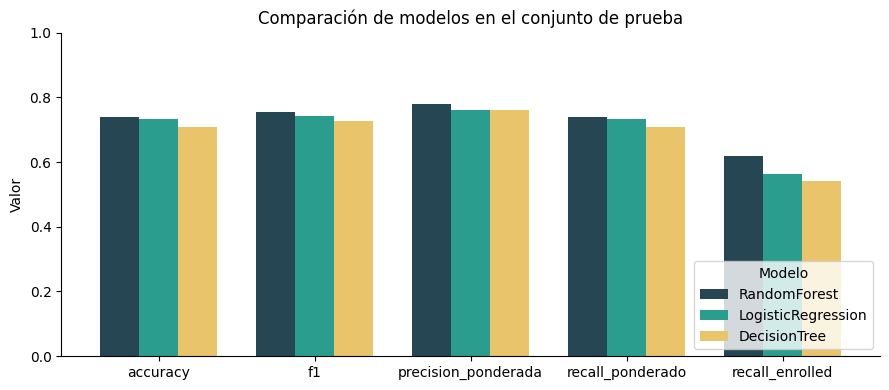

In [28]:
metricas_graf = ["accuracy", "f1", "precision_ponderada", "recall_ponderado", "recall_enrolled"]
ax = comparacion[metricas_graf].T.plot(kind="bar", figsize=(9, 4), color=["#264653", "#2a9d8f", "#e9c46a"], width=0.75)
ax.set_title("Comparación de modelos en el conjunto de prueba")
ax.set_ylim(0, 1)
ax.set_ylabel("Valor")
ax.set_xticklabels(metricas_graf, rotation=0)
ax.legend(title="Modelo", loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### 6.3 Selección del mejor modelo

**Qué hace:** elige el modelo con el **mayor F1 ponderado en prueba** y muestra sus hiperparámetros.

**Por qué el F1 ponderado como criterio:** con clases desbalanceadas, el F1 premia al modelo que mantiene buena precisión **y** buen recall en las tres clases, ponderando por el número de estudiantes de cada una; el *accuracy* podría elegir un modelo que ignore a *Enrolled*.

In [29]:
MEJOR = comparacion.index[0]
mejor_cv = modelos_cv[MEJOR]
mejor_modelo = mejor_cv.bestModel
print(f"Mejor modelo: {MEJOR}")
print(f"F1 ponderado (test): {comparacion.loc[MEJOR, 'f1']:.4f} | accuracy: {comparacion.loc[MEJOR, 'accuracy']:.4f} "
      f"| recall Enrolled: {comparacion.loc[MEJOR, 'recall_enrolled']:.4f}")
print("Hiperparámetros:", mejores_hp.set_index("modelo").loc[MEJOR, "mejores hiperparámetros"])

Mejor modelo: RandomForest
F1 ponderado (test): 0.7536 | accuracy: 0.7396 | recall Enrolled: 0.6181
Hiperparámetros: numTrees=50, maxDepth=10


### 6.4 Matriz de confusión y métricas por clase del mejor modelo

**Qué hace:** construye la matriz de confusión (filas = clase real, columnas = clase predicha) con un `groupBy` + `pivot` de Spark, la grafica como mapa de calor y calcula precisión, recall y F1 de cada clase.

**Por qué:** las métricas ponderadas resumen todo en un número; la matriz muestra **qué clases se confunden entre sí**, que es lo que realmente importa para la universidad (por ejemplo, cuántos *Dropout* se escapan como *Graduate*).

,Pred: Graduate,Pred: Dropout,Pred: Enrolled
Real: Graduate,349,16,78
Real: Dropout,18,184,52
Real: Enrolled,33,22,89


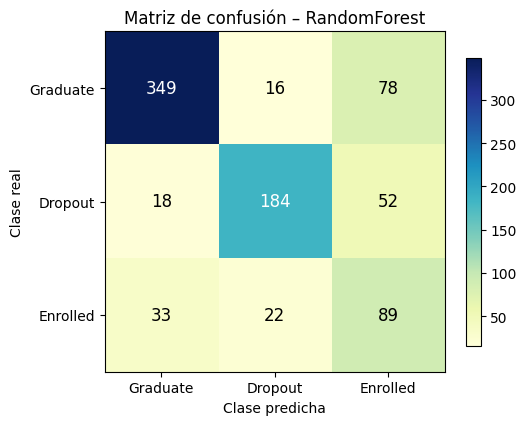

,precisión,recall,f1,soporte (test)
clase,,,,
Graduate,0.8725,0.7878,0.8280,443
Dropout,0.8288,0.7244,0.7731,254
Enrolled,0.4064,0.6181,0.4904,144


In [30]:
pred = predicciones_test[MEJOR]
matriz = (pred.groupBy("label").pivot("prediction", [float(i) for i in range(K)]).count()
          .fillna(0).orderBy("label").toPandas())
matriz.index = [f"Real: {LABELS[int(i)]}" for i in matriz["label"]]
matriz = matriz.drop(columns="label")
matriz.columns = [f"Pred: {LABELS[int(float(c))]}" for c in matriz.columns]
matriz = matriz.astype(int)
display(matriz)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(matriz.values, cmap="YlGnBu")
ax.set_xticks(range(K)); ax.set_xticklabels(LABELS)
ax.set_yticks(range(K)); ax.set_yticklabels(LABELS)
ax.set_xlabel("Clase predicha"); ax.set_ylabel("Clase real")
ax.set_title(f"Matriz de confusión – {MEJOR}")
umbral_color = matriz.values.max() / 2
for i in range(K):
    for j in range(K):
        v = matriz.values[i, j]
        ax.text(j, i, v, ha="center", va="center", color="white" if v > umbral_color else "black", fontsize=12)
fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

ev = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction")
por_clase = pd.DataFrame([{
    "clase": LABELS[i],
    "precisión": ev.evaluate(pred, {ev.metricName: "precisionByLabel", ev.metricLabel: float(i)}),
    "recall": ev.evaluate(pred, {ev.metricName: "recallByLabel", ev.metricLabel: float(i)}),
    "f1": ev.evaluate(pred, {ev.metricName: "fMeasureByLabel", ev.metricLabel: float(i)}),
    "soporte (test)": conteo_test[i],
} for i in range(K)]).set_index("clase").round(4)
por_clase

### 6.5 Prueba de control: ¿sirvieron los pesos por clase?

**Qué hace:** reentrena el mejor modelo **con los mismos hiperparámetros pero sin `weightCol`** y compara sus métricas en prueba con las del modelo con pesos.

**Por qué:** es la evidencia de que la estrategia de desbalance de la tarea 2 tuvo efecto. Si los pesos funcionan, el recall de *Enrolled* debe ser claramente mayor con pesos.

In [31]:
clf_mejor = mejor_modelo.stages[-1]
clf_sin_pesos = crear_clasificador(MEJOR, con_pesos=False)
for p in grillas[MEJOR][0]:
    clf_sin_pesos.set(clf_sin_pesos.getParam(p.name), clf_mejor.getOrDefault(clf_mejor.getParam(p.name)))

t0 = time.time()
modelo_sin_pesos = construir_pipeline(clf_sin_pesos, CAT_FINAL, NUM_FINAL).fit(train)
m_sin = evaluar(modelo_sin_pesos.transform(test))
m_con = comparacion.loc[MEJOR].to_dict()
control = pd.DataFrame({"con pesos": {k: m_con[k] for k in m_sin}, "sin pesos": m_sin}).round(4)
control["diferencia"] = (control["con pesos"] - control["sin pesos"]).round(4)
print(f"Modelo sin pesos entrenado en {time.time() - t0:.1f} s")
control

Modelo sin pesos entrenado en 11.1 s


,con pesos,sin pesos,diferencia
accuracy,0.7396,0.7705,-0.0309
f1,0.7536,0.7606,-0.0070
precision_ponderada,0.7795,0.7558,0.0237
recall_ponderado,0.7396,0.7705,-0.0309
recall_enrolled,0.6181,0.3611,0.2570
f1_enrolled,0.4904,0.4143,0.0761


### Justificación del mejor modelo

**El mejor modelo es el Random Forest** (`numTrees=50`, `maxDepth=10`):
1. **Mayor F1 ponderado en prueba (0,7536)**, por encima de la regresión logística (0,7435) y del árbol de decisión (0,7267). También tiene el mejor *accuracy* (0,7396) y la mejor precisión ponderada (0,7795).
2. **Es el que mejor detecta la clase minoritaria:** recall de *Enrolled* de **0,618** frente a 0,563 de la regresión logística y 0,542 del árbol. Considerando el desbalance, este es el criterio decisivo: el objetivo es encontrar a tiempo a los estudiantes en riesgo.
3. **Es consistente:** también fue el mejor en validación cruzada (0,7627), así que su ventaja no depende de una partición afortunada.
4. **Ganó con la hiperparametrización:** su F1 en prueba pasó de 0,724 (línea base: 20 árboles de profundidad 5) a 0,754. En la regresión logística la línea base sin regularización salió un poco mejor en prueba (0,750 vs 0,744), una diferencia del orden de la variación entre folds; la selección se hace por validación cruzada y no mirando la prueba, para no sobreajustar al conjunto de prueba.

**Lectura de la matriz de confusión**
- *Graduate* se reconoce muy bien (precisión 0,87, recall 0,79).
- De los 254 *Dropout* reales, el modelo identifica 184 (recall 0,72). Solo **18 desertores (7 %) se confunden con *Graduate***, el error más costoso porque el estudiante quedaría sin alerta; la mayoría de los errores de *Dropout* (52) caen en *Enrolled*, que igual es una señal de riesgo.
- *Enrolled* tiene buen recall (0,62) pero precisión baja (0,41): el modelo marca como *Enrolled* a 78 graduados y 52 desertores. Es el costo esperado de los pesos por clase y es aceptable en un sistema de alerta temprana: **revisar a un estudiante de más es mucho más barato que no detectar a uno en riesgo**.

**Efecto de los pesos por clase (prueba de control)**
Sin `weightCol`, el mismo modelo tiene más *accuracy* (0,771 vs 0,740) y un F1 ponderado algo mayor (0,761 vs 0,754), porque acierta más en la clase mayoritaria. Pero el **recall de *Enrolled* se desploma de 0,618 a 0,361**: dejaría sin detectar a casi 2 de cada 3 estudiantes *Enrolled*, y el F1 de esa clase baja de 0,490 a 0,414. Se acepta perder 0,007 de F1 ponderado a cambio de **+0,257 de recall en la clase minoritaria**, porque el propósito del sistema es la alerta temprana. Esto también confirma lo anticipado en la tarea 1: el *accuracy* no es una buena métrica para este problema.

### 6.6 Guardado del `PipelineModel` completo

**Qué hace:**
1. Guarda el `bestModel` del mejor `CrossValidator` (el `PipelineModel` completo: indexadores, codificador, ensamblador, escalador y clasificador) con `write().overwrite().save("modelo_final")`.
2. Dentro de la misma carpeta guarda dos archivos de apoyo para la app:
   - **`labels.json`**: el orden de las clases del `StringIndexer` (para traducir `prediction` y `probability`).
   - **`schema_entrada.json`**: las columnas que debe pedir el formulario, con su **tipo exacto** (entero o decimal). Si la app enviara, por ejemplo, `1.0` donde el modelo se entrenó con `1`, el `StringIndexer` vería un código distinto y lo mandaría a "desconocido" sin dar error.

**Por qué guardar el pipeline completo y no solo el clasificador:** así la app solo entrega datos crudos y el modelo aplica exactamente las mismas transformaciones del entrenamiento.

In [32]:
RUTA_MODELO = "modelo_final"
mejor_modelo.write().overwrite().save(RUTA_MODELO)

tipos_df = dict(train.dtypes)
columnas_modelo = set(CAT_FINAL) | set(NUM_FINAL)
columnas_formulario = [c for c in df.columns
                       if c not in EXCLUIR and (c in columnas_modelo or c in COLUMNAS_BASE_DERIVADAS)]

with open(os.path.join(RUTA_MODELO, "labels.json"), "w", encoding="utf-8") as f:
    json.dump(LABELS, f, ensure_ascii=False, indent=2)

schema_entrada = {
    "pyspark_version": pyspark.__version__,
    "modelo": MEJOR,
    "columnas": [{"nombre": c, "tipo": tipos_df[c], "categorica": c in CAT_FINAL} for c in columnas_formulario],
    "variables_derivadas": VARIABLES_DERIVADAS,
    "categoricas_modelo": CAT_FINAL,
    "numericas_modelo": NUM_FINAL,
}
with open(os.path.join(RUTA_MODELO, "schema_entrada.json"), "w", encoding="utf-8") as f:
    json.dump(schema_entrada, f, ensure_ascii=False, indent=2)

print(f"Modelo guardado en '{RUTA_MODELO}/' -> {sorted(os.listdir(RUTA_MODELO))}")
print(f"El formulario de la app pedirá {len(columnas_formulario)} variables.")

Modelo guardado en 'modelo_final/' -> ['labels.json', 'metadata', 'schema_entrada.json', 'stages']
El formulario de la app pedirá 18 variables.


### 6.7 Verificación: cargar el modelo guardado y predecir

**Qué hace:** carga el modelo con `PipelineModel.load` (exactamente como lo hará la app), predice 5 estudiantes de prueba y comprueba que las predicciones sean idénticas a las del modelo en memoria. Además prueba un estudiante con un **código de carrera inexistente** para confirmar que `handleInvalid="keep"` evita errores.

**Por qué:** detectar aquí cualquier problema de guardado es mucho más barato que descubrirlo con la app ya desplegada.

In [33]:
modelo_cargado = PipelineModel.load(RUTA_MODELO)
with open(os.path.join(RUTA_MODELO, "labels.json"), encoding="utf-8") as f:
    labels_cargados = json.load(f)

muestra = test.limit(5)
original = [r["prediction"] for r in mejor_modelo.transform(muestra).select("prediction").collect()]
recargado = modelo_cargado.transform(muestra).select("target", "prediction", "probability").collect()
assert original == [r["prediction"] for r in recargado], "Las predicciones no coinciden"

display(pd.DataFrame([{
    "clase real": r["target"],
    "clase predicha": labels_cargados[int(r["prediction"])],
    **{f"P({c})": round(float(p), 3) for c, p in zip(labels_cargados, r["probability"].toArray())},
} for r in recargado]))

if "course" in CAT_FINAL:
    raro = modelo_cargado.transform(muestra.limit(1).withColumn("course", F.lit(1234))).first()
    print(f"Carrera inexistente (1234) -> predicción: {labels_cargados[int(raro['prediction'])]} (sin error)")
print("✅ El modelo guardado carga y predice igual que el modelo en memoria.")

,clase real,clase predicha,P(Graduate),P(Dropout),P(Enrolled)
0,Dropout,Graduate,0.409,0.339,0.253
1,Graduate,Graduate,0.497,0.186,0.317
2,Graduate,Dropout,0.289,0.486,0.224
3,Enrolled,Dropout,0.270,0.465,0.265
4,Enrolled,Enrolled,0.333,0.194,0.473


Carrera inexistente (1234) -> predicción: Dropout (sin error)
✅ El modelo guardado carga y predice igual que el modelo en memoria.


### 6.8 Comprimir la carpeta del modelo en un ZIP y descargarla

**Qué hace:** comprime `modelo_final/` (con `labels.json` y `schema_entrada.json` adentro) en `modelo_final.zip` y, en Colab, lo descarga automáticamente.

**Por qué:** el enunciado pide entregar la carpeta del modelo en un ZIP, y ese mismo archivo es el que se descomprime en el proyecto de Visual Studio Code para construir la app de Streamlit. Al descomprimirlo, dentro de `modelo_final/` deben quedar directamente las carpetas `metadata/` y `stages/`.

In [34]:
archivo_zip = shutil.make_archive("modelo_final", "zip", root_dir=".", base_dir=RUTA_MODELO)
print(f"ZIP creado: {archivo_zip} ({os.path.getsize(archivo_zip) / 1024:.1f} KB)")

if EN_COLAB:
    from google.colab import files
    files.download(archivo_zip)

ZIP creado: /content/modelo_final.zip (365.4 KB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
## Conclusiones

| Paso | Resultado |
|---|---|
| Datos | 4.424 estudiantes, sin duplicados ni nulos; Graduate 49,9 %, Dropout 32,1 %, Enrolled 17,9 % |
| Desbalance | Pesos por clase + F1 ponderado: el recall de *Enrolled* pasa de 0,36 a 0,62 |
| Ingeniería | 5 variables derivadas; 3 de ellas están en el top 4 de importancia |
| Selección | De 39 a 23 variables con una pérdida mínima de F1 en CV (−0,004) |
| Mejor modelo | Random Forest (50 árboles, profundidad 10): **F1 = 0,754**, accuracy = 0,740 en prueba |
| Artefactos | `modelo_final/` (PipelineModel + `labels.json` + `schema_entrada.json`) y `modelo_final.zip` |

**Siguiente paso:** cargar `modelo_final` en la app de Streamlit con `PipelineModel.load`, calcular allí las mismas variables derivadas y mostrar la clase predicha con la probabilidad de cada clase.